Setup

In [41]:
# Standard setup cell - run before other cells.
import importlib.util
import itertools
import math
import subprocess
import sys


def ensure_dependencies():
    """Install only packages used by this notebook."""
    required = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib"}
    missing = [pkg for mod, pkg in required.items() if importlib.util.find_spec(mod) is None]
    if missing:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)


ensure_dependencies()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

VALUES = (True, False)
print("Python:", sys.version.split()[0])
print("Setup selesai. Variabel jaringan memakai True dan False.")

Python: 3.12.4
Setup selesai. Variabel jaringan memakai True dan False.


Soal 1 - Jawaban Penjelasan

1.
parent dan child dari Alarm:
Parent: Burglary dan Earthquake.   
Child: JohnCalls dan MaryCalls.   
Alasan DAG gak boleh ada siklus berarah: bayesian network pake struktur DAG (directed acyclic graph) buat nentuin urutan kausalitas/probabilitas. kalau ada siklus berarah (loop), kalkulasi chain rule buat nyari joint probability bakal muter terus tanpa ujung dan bikin probabilitasnya gak terdefinisi dengan benar.   

2.
hitung P(A=False | B=False, E=True):
dari CPT Alarm di modul, nilai P(Alarm=True | B=False, E=True) = 0.29.   
karena komplemennya: P(A=False | B=False, E=True) = 1 - 0.29 = 0.71.   
baris CPT yang dipakai yaitu tuple (False, True) pada node Alarm.   

3.
hitung P(¬b, e, a, j, ¬m):
rumusnya: P(¬b) * P(e) * P(a | ¬b, e) * P(j | a) * P(¬m | a)   
P(¬b) = 1 - 0.001 = 0.999   
P(e) = 0.002   
P(a | ¬b, e) = 0.29   
P(j | a) = 0.90   
P(¬m | a) = 1 - 0.70 = 0.30   
P(¬b, e, a, j, ¬m) = 0.999 * 0.002 * 0.29 * 0.90 * 0.30 = 0.0001564434   

4.
perbedaan P(b, j, m) dan P(b | j, m):
P(b, j, m) itu probabilitas joint marginal (seberapa sering ketiga kejadian ini terjadi barengan tanpa nemu kondisi pasti). didapat dari nge-sumsemua kombinasi variabel hidden (Earthquake dan Alarm).   
P(b | j, m) itu probabilitas bersyarat/posterior (peluang pencurian kalau udah tau john dan mary beneran nelfon). nilainya dapet dari bagi P(b, j, m) sama total P(j, m) (normalisasi).   
Earthquake dan Alarm diikutsertakan sebagai variabel hidden di mana nilainya di-sum out untuk semua kemungkinan True/False.  

5.
kenapa CPT JohnCalls cukup pake Alarm sebagai parent:

berdasarkan asumsi independensi bersyarat (conditional independence), john nelfon cuma dipengaruhi langsung sama bunyi alarm. kalau status Alarm udah diketahui, john gak peduli bunyi alarm itu gara2 pencurian atau gempa (J ⊥ {B, E} | A).   

In [42]:
# gabungan definisi & eksekusi soal 1
burglary = {
    "Burglary": {"parents": (), "cpt": {(): 0.001}},
    "Earthquake": {"parents": (), "cpt": {(): 0.002}},
    "Alarm": {
        "parents": ("Burglary", "Earthquake"),
        "cpt": {(True, True): 0.95, (True, False): 0.94,
                (False, True): 0.29, (False, False): 0.001},
    },
    "JohnCalls": {"parents": ("Alarm",), "cpt": {(True,): 0.90, (False,): 0.05}},
    "MaryCalls": {"parents": ("Alarm",), "cpt": {(True,): 0.70, (False,): 0.01}},
}

def node_probability(variable, value, event, network):
    node = network[variable]
    parent_values = tuple(event[parent] for parent in node["parents"])
    p_true = node["cpt"][parent_values]
    return p_true if value else 1 - p_true

def joint_probability(event, network):
    return math.prod(node_probability(variable, event[variable], event, network) for variable in network)

event1 = {"Burglary": False, "Earthquake": True, "Alarm": True, "JohnCalls": True, "MaryCalls": False}
p1 = joint_probability(event1, burglary)
p_a_false = 1 - burglary["Alarm"]["cpt"][(False, True)]

print(f"p(a=false | b=false, e=true) = {p_a_false:.2f}")
print(f"p(not b, e, a, j, not m) = {p1:.10f}")

p(a=false | b=false, e=true) = 0.71
p(not b, e, a, j, not m) = 0.0001564434


Soal 2 - Jawaban Penjelasan

1.
kalkulasi posterior B=True pake enumeration_ask ada di cell kode di bawah.   

2.
analisis query 1 P(B=True | M=True):
Query: Burglary   
Evidence: MaryCalls=True   
Hidden: Earthquake, Alarm, JohnCalls   
jumlah kombinasi hidden: ada 3 variabel boolean hidden, jd 2^3 = 8 kombinasi diperiksa buat tiap kandidat nilai Burglary (True & False).

3.
verifikasi query 2 P(B=True | M=True, J=False) pake full_joint dijalanin di cell kode bawah, hasilnya persis cocok pake np.isclose.

4.
pengaruh gak nyantumkan vs nge-set False:kalau JohnCalls gak dicantumkan di evidence, dia jadi variabel hidden yang nilainya bisa True atau False (dijumlahin keduanya).   
kalau JohnCalls=False, kita dapet fakta pasti john gak nelfon yang bikin peluang pencurian makin kecil dibanding pas john gak ketahuan nelfon atau gak.  

In [43]:
# soal 2 - self-contained code
import numpy as np
import pandas as pd

VALUES = (True, False)

def all_events(variables):
    variables = list(variables)
    for values in itertools.product(VALUES, repeat=len(variables)):
        yield dict(zip(variables, values))

def normalize(scores):
    total = sum(scores.values())
    if total <= 0:
        raise ValueError("Cannot normalize zero total probability or weight")
    return {value: score / total for value, score in scores.items()}

def check_query(query, evidence, network):
    if query not in network or not set(evidence) <= set(network):
        raise ValueError("Unknown query or evidence variable")
    if query in evidence:
        raise ValueError("Query must be distinct from evidence")

def enumeration_ask(query, evidence, network):
    check_query(query, evidence, network)
    hidden = [variable for variable in network if variable != query and variable not in evidence]
    scores = {}
    for value in VALUES:
        scores[value] = sum(
            joint_probability({**evidence, query: value, **hidden_event}, network)
            for hidden_event in all_events(hidden)
        )
    return normalize(scores)

q1 = enumeration_ask("Burglary", {"MaryCalls": True}, burglary)[True]
q2 = enumeration_ask("Burglary", {"MaryCalls": True, "JohnCalls": False}, burglary)[True]
q3 = enumeration_ask("Burglary", {"MaryCalls": True, "JohnCalls": True}, burglary)[True]

print(f"p(b=true | m=true) = {q1:.6f}")
print(f"p(b=true | m=true, j=false) = {q2:.6f}")
print(f"p(b=true | m=true, j=true) = {q3:.6f}")

full_joint = pd.DataFrame([{**ev, "probability": joint_probability(ev, burglary)} for ev in all_events(burglary)])
df_ev = full_joint[full_joint["MaryCalls"] & (~full_joint["JohnCalls"])]
sum_b = df_ev.groupby("Burglary")["probability"].sum()
q2_fj = sum_b[True] / sum_b.sum()

print(f"hasil full_joint q2 = {q2_fj:.6f}")
print("cocok:", np.isclose(q2, q2_fj))

p(b=true | m=true) = 0.056117
p(b=true | m=true, j=false) = 0.006876
p(b=true | m=true, j=true) = 0.284172
hasil full_joint q2 = 0.006876
cocok: True


Soal 3 - Jawaban Penjelasan

1.
graf dan dictionary campus_network diset dengan node Rain -> Traffic -> Late dan Rain -> Late.

2.
faktorisasi joint distribution:

P(Rain, Traffic, Late) = P(Rain) * P(Traffic | Rain) * P(Late | Rain, Traffic)   

3.
nilai P(Late=True) dihitung pake enumeration_ask atau penjumlahan 4 kombinasi.   

4.
nilai posterior P(Rain=True | Late=True) dan P(Traffic=True | Late=True) dihitung di kode.   
artinya: kalau mahasiswa udah terlambat, peluang harinya hujan naik drastis dari prior 0.30, begitu juga peluang macet naik dari prior awal.   

5.
apakah Rain dan Late independen setelah Traffic diketahui:
tidak independen. karena selain lewat path Rain -> Traffic -> Late, masih ada direct path (panah langsung) dari Rain -> Late.   
liat CPT Late pas Traffic=True: P(Late=True | Rain=True, Traffic=True) = 0.90 sedangkan P(Late=True | Rain=False, Traffic=True) = 0.60 (nilainya beda, jadi rain tetep ngebawa pengaruh ke late meski traffic udah tau).

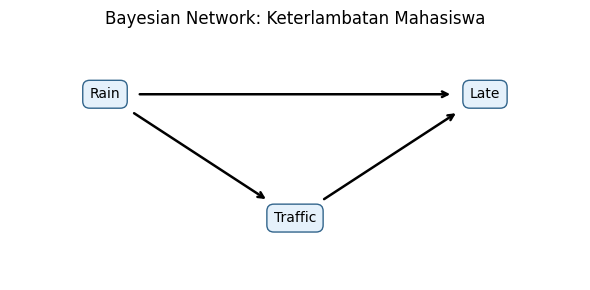

total probabilitas joint =  1.0


,Rain,Traffic,Late,probability
0,True,True,True,0.216
1,True,True,False,0.024
2,True,False,True,0.030
3,True,False,False,0.030
4,False,True,True,0.084
5,False,True,False,0.056
6,False,False,True,0.028
7,False,False,False,0.532


p(late=true) = 0.358000
p(rain=true | late=true) = 0.687151
p(traffic=true | late=true) = 0.837989


In [44]:
# soal 3 - self-contained code with graph plot
import itertools
import math
import matplotlib.pyplot as plt

VALUES = (True, False)

def all_events(variables):
    variables = list(variables)
    for values in itertools.product(VALUES, repeat=len(variables)):
        yield dict(zip(variables, values))

def normalize(scores):
    total = sum(scores.values())
    if total <= 0:
        raise ValueError("Cannot normalize zero total probability or weight")
    return {value: score / total for value, score in scores.items()}

def check_query(query, evidence, network):
    if query not in network or not set(evidence) <= set(network):
        raise ValueError("Unknown query or evidence variable")
    if query in evidence:
        raise ValueError("Query must be distinct from evidence")

def node_probability(variable, value, event, network):
    node = network[variable]
    parent_values = tuple(event[parent] for parent in node["parents"])
    p_true = node["cpt"][parent_values]
    return p_true if value else 1 - p_true

def joint_probability(event, network):
    return math.prod(node_probability(variable, event[variable], event, network) for variable in network)

def enumeration_ask(query, evidence, network):
    check_query(query, evidence, network)
    hidden = [variable for variable in network if variable != query and variable not in evidence]
    scores = {}
    for value in VALUES:
        scores[value] = sum(
            joint_probability({**evidence, query: value, **hidden_event}, network)
            for hidden_event in all_events(hidden)
        )
    return normalize(scores)

def validate_network(network):
    seen = set()
    for variable, node in network.items():
        parents = node["parents"]
        if len(parents) != len(set(parents)) or not set(parents) <= seen:
            raise ValueError(f"Invalid parent order for {variable}")
        expected = set(itertools.product(VALUES, repeat=len(parents)))
        if set(node["cpt"]) != expected:
            raise ValueError(f"Incomplete CPT for {variable}")
        seen.add(variable)

campus_network = {
    "Rain": {"parents": (), "cpt": {(): 0.30}},
    "Traffic": {
        "parents": ("Rain",),
        "cpt": {(True,): 0.80, (False,): 0.20}
    },
    "Late": {
        "parents": ("Rain", "Traffic"),
        "cpt": {
            (True, True): 0.90,
            (True, False): 0.50,
            (False, True): 0.60,
            (False, False): 0.05
        }
    }
}

validate_network(campus_network)

# 1. gambar graf
positions = {"Rain": (0, 1), "Traffic": (1, 0), "Late": (2, 1)}
fig, ax = plt.subplots(figsize=(6, 3))
for child, node in campus_network.items():
    for parent in node["parents"]:
        ax.annotate("", xy=positions[child], xytext=positions[parent],
                    arrowprops={"arrowstyle": "->", "lw": 1.8, "shrinkA": 25, "shrinkB": 25})
for variable, (x, y) in positions.items():
    ax.text(x, y, variable, ha="center", va="center",
            bbox={"boxstyle": "round,pad=0.5", "fc": "#e5f1fb", "ec": "#32658c"})
ax.set(xlim=(-0.5, 2.5), ylim=(-0.5, 1.5), title="Bayesian Network: Keterlambatan Mahasiswa")
ax.axis("off")
plt.tight_layout()
plt.show()

# 2. tabel joint & kalkulasi
rows_campus = []
for ev in all_events(campus_network):
    p = joint_probability(ev, campus_network)
    rows_campus.append({**ev, "probability": p})
df_campus = pd.DataFrame(rows_campus)

print("total probabilitas joint = ", df_campus["probability"].sum())
display(df_campus)

p_late = enumeration_ask("Late", {}, campus_network)[True]
p_rain_given_late = enumeration_ask("Rain", {"Late": True}, campus_network)[True]
p_traffic_given_late = enumeration_ask("Traffic", {"Late": True}, campus_network)[True]

print(f"p(late=true) = {p_late:.6f}")
print(f"p(rain=true | late=true) = {p_rain_given_late:.6f}")
print(f"p(traffic=true | late=true) = {p_traffic_given_late:.6f}")

Soal 4 - Jawaban Penjelasan

1.
ekspresi P(B | j, ¬m) dalam bentuk perkalian CPT dan penjumlahan hidden:
P(B, j, ¬m) = P(B) * sum_E ( P(E) * sum_A ( P(A | B, E) * P(j | A) * P(¬m | A) ) )   
P(B | j, ¬m) = normalize( P(B, j, ¬m) )  

2.
langkah variable elimination disesuaikan di cell code bawah. 

3.
perbandingan hasil Burglary=True dan False cocok sama enumeration_ask pake np.isclose.   
factor f(B, A) dari 2.5 tetep bisa dipakai ulang karena cuma ngelibatin kombinasi Earthquake dan Alarm. yang diubah cuma g(B) pas dikali CPT MaryCalls yang pake nilai False (1 - P(M=True | A)). 

4.
perbandingan P(B=True | A=True, E=False) vs P(B=True | A=True, E=True):
pas E=False: peluang pencurian tinggi banget karena alarm bunyi bukan gara2 gempa.   
pas E=True: peluang pencurian turun drastis (explaining away) karena keberadaan gempa udah ngejelasin kenapa alarm bisa bunyi.  

5.
independensi Burglary dan Earthquake:
sebelum ada evidence: independen, karena P(B=True | E=True) == P(B=True) = 0.001.   
setelah Alarm=True diketahui: tidak independen lagi gara2 efek collider / explaining away.   

In [45]:
# soal 4 - self-contained code
burglary = {
    "Burglary": {"parents": (), "cpt": {(): 0.001}},
    "Earthquake": {"parents": (), "cpt": {(): 0.002}},
    "Alarm": {
        "parents": ("Burglary", "Earthquake"),
        "cpt": {(True, True): 0.95, (True, False): 0.94,
                (False, True): 0.29, (False, False): 0.001},
    },
    "JohnCalls": {"parents": ("Alarm",), "cpt": {(True,): 0.90, (False,): 0.05}},
    "MaryCalls": {"parents": ("Alarm",), "cpt": {(True,): 0.70, (False,): 0.01}},
}

factor_ba = {}
for b, a in itertools.product(VALUES, repeat=2):
    factor_ba[b, a] = sum(
        node_probability("Earthquake", e, {}, burglary)
        * node_probability("Alarm", a, {"Burglary": b, "Earthquake": e}, burglary)
        for e in VALUES
    )

print("--- Factor f(B, A) sementara ---")
display(pd.DataFrame([{"Burglary": b, "Alarm": a, "f(B,A)": val} for (b, a), val in factor_ba.items()]))

scores_s4 = {}
for b in VALUES:
    g_b = sum(
        factor_ba[b, a]
        * node_probability("JohnCalls", True, {"Alarm": a}, burglary)
        * node_probability("MaryCalls", False, {"Alarm": a}, burglary)
        for a in VALUES
    )
    scores_s4[b] = node_probability("Burglary", b, {}, burglary) * g_b

print("\nNilai sebelum normalisasi (P(B, j, not m)):", scores_s4)

res_ve = normalize(scores_s4)
res_enum = enumeration_ask("Burglary", {"JohnCalls": True, "MaryCalls": False}, burglary)

print("hasil VE  :", res_ve)
print("hasil enum:", res_enum)
print("cocok:", all(np.isclose(res_ve[v], res_enum[v]) for v in VALUES))

p_b_given_a_not_e = enumeration_ask("Burglary", {"Alarm": True, "Earthquake": False}, burglary)[True]
p_b_given_a_e = enumeration_ask("Burglary", {"Alarm": True, "Earthquake": True}, burglary)[True]

print(f"\np(b=true | a=true, e=false) = {p_b_given_a_not_e:.6f}")
print(f"p(b=true | a=true, e=true) = {p_b_given_a_e:.6f}")

--- Factor f(B, A) sementara ---


,Burglary,Alarm,"f(B,A)"
0,True,True,0.940020
1,True,False,0.059980
2,False,True,0.001578
3,False,False,0.998422



Nilai sebelum normalisasi (P(B, j, not m)): {True: 0.00025677441, False: 0.04979810105099999}
hasil VE  : {True: 0.0051298581334013015, False: 0.9948701418665987}
hasil enum: {True: 0.0051298581334013, False: 0.9948701418665987}
cocok: True

p(b=true | a=true, e=false) = 0.484786
p(b=true | a=true, e=true) = 0.003268


Soal 5 - Jawaban Penjelasan

1 - 3. 
hasil percobaan eksperimen sampling untuk seed 7, 21, 42 dan sampel 100, 1000, 10000 ada di tabel dan grafik bawah.   
galat gak selalu turun di tiap penambahan sampel buat seed tertentu karena sampling itu proses acak (stokastik). tapi secara rata-rata (mean error dari 3 seed), makin banyak sampel emang galatnya makin ngekecil dan makin stabil.  

4.
hitung P(J=True, M=True) dari full_joint:
P(J=True, M=True) ≈ 0.002084.   
estimasi sampel diterima dari 1.000 sampel = 1000 * 0.002084 ≈ 2 sampel.   
perbandingan hasil run nyata ada di output cell kode.  

5.
kendala metode sampling:
kalau nentuin evidence tanpa pembobotan (prior/rejection), distribusi sampel gak sesuai posterior sejati.   
Rejection Sampling: jelek pas evidence langka/jarang terjadi (banyak sampel dibuang).   
Likelihood Weighting: kalau bobot dominan cuma ada di dikit sampel, estimasinya gak stabil.   
Gibbs Sampling: sampel antar sweep saling berkorelasi (dependent), butuh burn-in yang pas dan bisa terjebak di state lokal kalau CPT mendekati 0 atau 1.   

,metode,seed,jumlah sampel,taksiran,galat absolut,diterima
0,Rejection,7,100,0.712121,0.004194,66.0
1,Likelihood Weighting,7,100,0.792899,0.084972,NaN
2,Gibbs,7,100,0.680000,0.027928,NaN
3,Rejection,21,100,0.611940,0.095987,67.0
4,Likelihood Weighting,21,100,0.629156,0.078772,NaN
5,Gibbs,21,100,0.740000,0.032072,NaN
6,Rejection,42,100,0.691176,0.016751,68.0
7,Likelihood Weighting,42,100,0.742268,0.034340,NaN
8,Gibbs,42,100,0.740000,0.032072,NaN
9,Rejection,7,1000,0.714286,0.006358,637.0


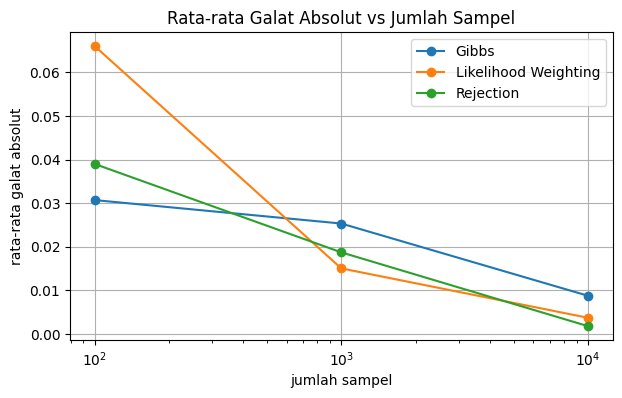

p(j=true, m=true) = 0.002084
perkiraan sampel diterima dr 1000 = 2.08
seed 7 -> diterima: 1 sampel
seed 21 -> diterima: 2 sampel
seed 42 -> diterima: 1 sampel


In [46]:
# soal 5 - self-contained code with plot
import matplotlib.pyplot as plt

sprinkler = {
    "Cloudy": {"parents": (), "cpt": {(): 0.5}},
    "Sprinkler": {"parents": ("Cloudy",), "cpt": {(True,): 0.1, (False,): 0.5}},
    "Rain": {"parents": ("Cloudy",), "cpt": {(True,): 0.8, (False,): 0.2}},
    "WetGrass": {
        "parents": ("Sprinkler", "Rain"),
        "cpt": {(True, True): 0.99, (True, False): 0.90,
                (False, True): 0.90, (False, False): 0.0},
    },
}

def prior_sample(network, rng):
    event = {}
    for variable in network:
        p_true = node_probability(variable, True, event, network)
        event[variable] = bool(rng.random() < p_true)
    return event

def rejection_sampling(query, evidence, network, sample_count, rng):
    check_query(query, evidence, network)
    counts = {True: 0, False: 0}
    for _ in range(sample_count):
        event = prior_sample(network, rng)
        if all(event[variable] == value for variable, value in evidence.items()):
            counts[event[query]] += 1
    accepted = sum(counts.values())
    return (normalize(counts) if accepted else None), accepted

def weighted_sample(evidence, network, rng):
    event = {}
    weight = 1.0
    for variable in network:
        if variable in evidence:
            event[variable] = evidence[variable]
            weight *= node_probability(variable, event[variable], event, network)
        else:
            p_true = node_probability(variable, True, event, network)
            event[variable] = bool(rng.random() < p_true)
    return event, weight

def likelihood_weighting(query, evidence, network, sample_count, rng):
    check_query(query, evidence, network)
    weights = {True: 0.0, False: 0.0}
    for _ in range(sample_count):
        event, weight = weighted_sample(evidence, network, rng)
        weights[event[query]] += weight
    return normalize(weights)

def gibbs_ask(query, evidence, network, sample_count, rng, burn_in=500):
    check_query(query, evidence, network)
    free = [variable for variable in network if variable not in evidence]
    state = next(
        ({**event, **evidence} for event in all_events(free)
         if joint_probability({**event, **evidence}, network) > 0), None)
    if state is None:
        raise ValueError("Evidence has zero probability")
    children = {variable: [child for child, node in network.items()
                           if variable in node["parents"]] for variable in network}
    counts = {True: 0, False: 0}
    for sweep in range(burn_in + sample_count):
        for variable in free:
            scores = {}
            for value in VALUES:
                state[variable] = value
                scores[value] = node_probability(variable, value, state, network) * math.prod(
                    node_probability(child, state[child], state, network)
                    for child in children[variable])
            p_true = normalize(scores)[True]
            state[variable] = bool(rng.random() < p_true)
        if sweep >= burn_in:
            counts[state[query]] += 1
    return normalize(counts)

exact_sprinkler = enumeration_ask("Rain", {"WetGrass": True}, sprinkler)[True]

seeds = [7, 21, 42]
sample_sizes = [100, 1000, 10000]
results_s5 = []

for N in sample_sizes:
    for seed in seeds:
        res_rej, acc = rejection_sampling("Rain", {"WetGrass": True}, sprinkler, N, np.random.default_rng(seed))
        est_rej = res_rej[True] if res_rej is not None else np.nan
        err_rej = abs(est_rej - exact_sprinkler) if not np.isnan(est_rej) else np.nan
        results_s5.append({"metode": "Rejection", "seed": seed, "jumlah sampel": N, "taksiran": est_rej, "galat absolut": err_rej, "diterima": acc})
        
        res_lw = likelihood_weighting("Rain", {"WetGrass": True}, sprinkler, N, np.random.default_rng(seed))
        est_lw = res_lw[True]
        results_s5.append({"metode": "Likelihood Weighting", "seed": seed, "jumlah sampel": N, "taksiran": est_lw, "galat absolut": abs(est_lw - exact_sprinkler), "diterima": np.nan})
        
        res_gb = gibbs_ask("Rain", {"WetGrass": True}, sprinkler, N, np.random.default_rng(seed), burn_in=500)
        est_gb = res_gb[True]
        results_s5.append({"metode": "Gibbs", "seed": seed, "jumlah sampel": N, "taksiran": est_gb, "galat absolut": abs(est_gb - exact_sprinkler), "diterima": np.nan})

df_s5 = pd.DataFrame(results_s5)
display(df_s5.round(6))

df_avg = df_s5.groupby(["metode", "jumlah sampel"])["galat absolut"].mean().reset_index()

plt.figure(figsize=(7, 4))
for m in df_avg["metode"].unique():
    sub = df_avg[df_avg["metode"] == m]
    plt.plot(sub["jumlah sampel"], sub["galat absolut"], marker="o", label=m)

plt.xscale("log")
plt.xlabel("jumlah sampel")
plt.ylabel("rata-rata galat absolut")
plt.title("Rata-rata Galat Absolut vs Jumlah Sampel")
plt.legend()
plt.grid(True)
plt.show()

p_jm = full_joint[full_joint["JohnCalls"] & full_joint["MaryCalls"]]["probability"].sum()
print(f"p(j=true, m=true) = {p_jm:.6f}")
print(f"perkiraan sampel diterima dr 1000 = {1000 * p_jm:.2f}")

for s in seeds:
    _, acc_alarm = rejection_sampling("Burglary", {"JohnCalls": True, "MaryCalls": True}, burglary, 1000, np.random.default_rng(s))
    print(f"seed {s} -> diterima: {acc_alarm} sampel")